In [40]:
# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures # Added PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso     # Removed PolynomialRegression
from sklearn.tree import DecisionTreeRegressor                      # Moved to .tree
from sklearn.svm import SVR                                         # Moved to .svm and fixed typo
from sklearn.neighbors import KNeighborsRegressor                   # Moved to .neighbors and fixed capitalization
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [41]:
# STEP 2: LOAD DATASET

df = pd.read_csv("/content/StudentPerformanceFactors-selected-columns.csv")

df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Internet_Access,Tutoring_Sessions,Teacher_Quality,Physical_Activity,Exam_Score
0,23,84,Low,High,No,7,73,Yes,0,Medium,3,67
1,19,64,Low,Medium,No,8,59,Yes,2,Medium,4,61
2,24,98,Medium,Medium,Yes,7,91,Yes,2,Medium,4,74
3,29,89,Low,Medium,Yes,8,98,Yes,1,Medium,4,71
4,19,92,Medium,Medium,Yes,6,65,Yes,3,High,4,70


In [42]:
# STEP 3: BASIC INFORMATION

print("Dataset Shape:", df.shape)

df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (6607, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Internet_Access             6607 non-null   object
 8   Tutoring_Sessions           6607 non-null   int64 
 9   Teacher_Quality             6529 non-null   object
 10  Physical_Activity           6607 non-null   int64 
 11  Exam_Score                  6607 non-null   int64 
dtypes: int64(7), object(5)
memory usage: 619.5+ KB

Statistical Summary:


,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


### Select 8 Key Features for Student Marks Prediction
We will define the target variable `Exam_Score` and select 8 relevant features from the student performance factors dataset to train our model.

In [43]:
# Define the target and select exactly 8 student features
target = 'Exam_Score'

# Choosing 8 relevant features
features_8 = [
    'Hours_Studied',
    'Attendance',
    'Parental_Involvement',
    'Access_to_Resources',
    'Extracurricular_Activities',
    'Sleep_Hours',
    'Previous_Scores',
    'Tutoring_Sessions'
]

# Filter DataFrame to keep only target and chosen features
student_df = df[features_8 + [target]].copy()
print("Selected Student Dataset Shape:", student_df.shape)
display(student_df.head())

Selected Student Dataset Shape: (6607, 9)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Exam_Score
0,23,84,Low,High,No,7,73,0,67
1,19,64,Low,Medium,No,8,59,2,61
2,24,98,Medium,Medium,Yes,7,91,2,74
3,29,89,Low,Medium,Yes,8,98,1,71
4,19,92,Medium,Medium,Yes,6,65,3,70


### Clean and Encode Student Features
Next, we handle categorical encoding for variables such as `Parental_Involvement` and `Extracurricular_Activities`.

In [44]:
# Drop rows with missing values in our chosen subset
student_df = student_df.dropna()

# Identify categorical columns among the 8 features
cat_cols = student_df[features_8].select_dtypes(include=['object', 'category']).columns.tolist()

# One-hot encode categorical features
student_df_encoded = pd.get_dummies(student_df, columns=cat_cols, drop_first=True, dtype=int)

# Separate X and y
X_student = student_df_encoded.drop(columns=[target])
y_student = student_df_encoded[target]

print("Encoded Features shape:", X_student.shape)
print("Features list after encoding:", X_student.columns.tolist())

Encoded Features shape: (6607, 10)
Features list after encoding: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Parental_Involvement_Low', 'Parental_Involvement_Medium', 'Access_to_Resources_Low', 'Access_to_Resources_Medium', 'Extracurricular_Activities_Yes']


In [45]:
# STEP 4: MISSING VALUES

print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Internet_Access                0
Tutoring_Sessions              0
Teacher_Quality               78
Physical_Activity              0
Exam_Score                     0
dtype: int64

Total Missing Values: 78


In [46]:
# STEP 5: DUPLICATE VALUES

print("Exact Duplicate Rows:", df.duplicated().sum())

# print("Repeated Track IDs:", df["track_id"].duplicated().sum())

Exact Duplicate Rows: 0


In [47]:
# STEP 6: CLEAN DATASET
# Reset index and verify we are working with our prepared 8-feature student dataframe
student_df = student_df.reset_index(drop=True)
print("Cleaned Student Dataset Shape:", student_df.shape)
print("\nMissing Values after handling:")
print(student_df.isnull().sum())

Cleaned Student Dataset Shape: (6607, 9)

Missing Values after handling:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Tutoring_Sessions             0
Exam_Score                    0
dtype: int64


In [48]:
# STEP 9: ENCODE ALL CATEGORICAL COLUMNS

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical Columns:", categorical_cols)

df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Encoded Dataset Shape:", df.shape)

print("\nEncoded Columns:")
print(df.columns.tolist())

Categorical Columns: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Internet_Access', 'Teacher_Quality']
Encoded Dataset Shape: (6607, 15)

Encoded Columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score', 'Parental_Involvement_Low', 'Parental_Involvement_Medium', 'Access_to_Resources_Low', 'Access_to_Resources_Medium', 'Extracurricular_Activities_Yes', 'Internet_Access_Yes', 'Teacher_Quality_Low', 'Teacher_Quality_Medium']


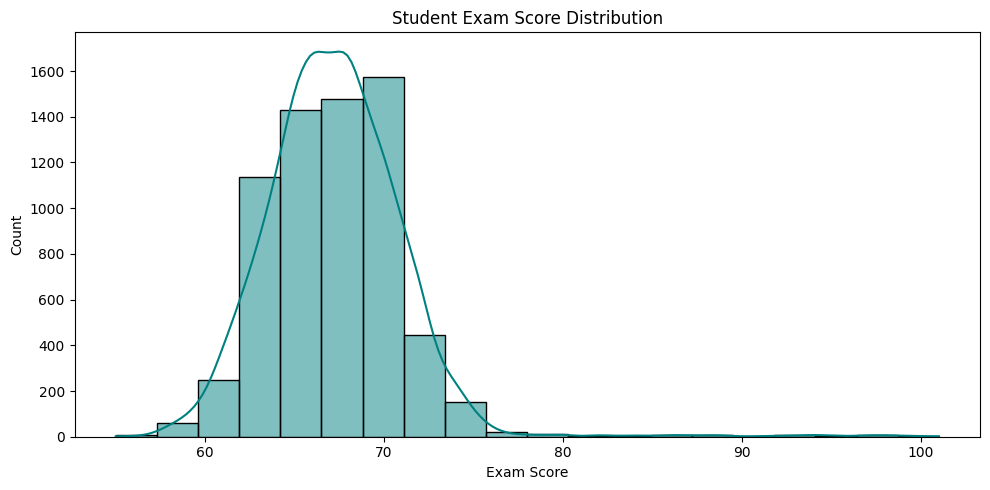

In [49]:
# STEP 7: EXAM SCORE (TARGET) DISTRIBUTION
plt.figure(figsize=(10, 5))
sns.histplot(
    student_df["Exam_Score"],
    bins=20,
    kde=True,
    color='teal'
)
plt.title("Student Exam Score Distribution")
plt.xlabel("Exam Score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

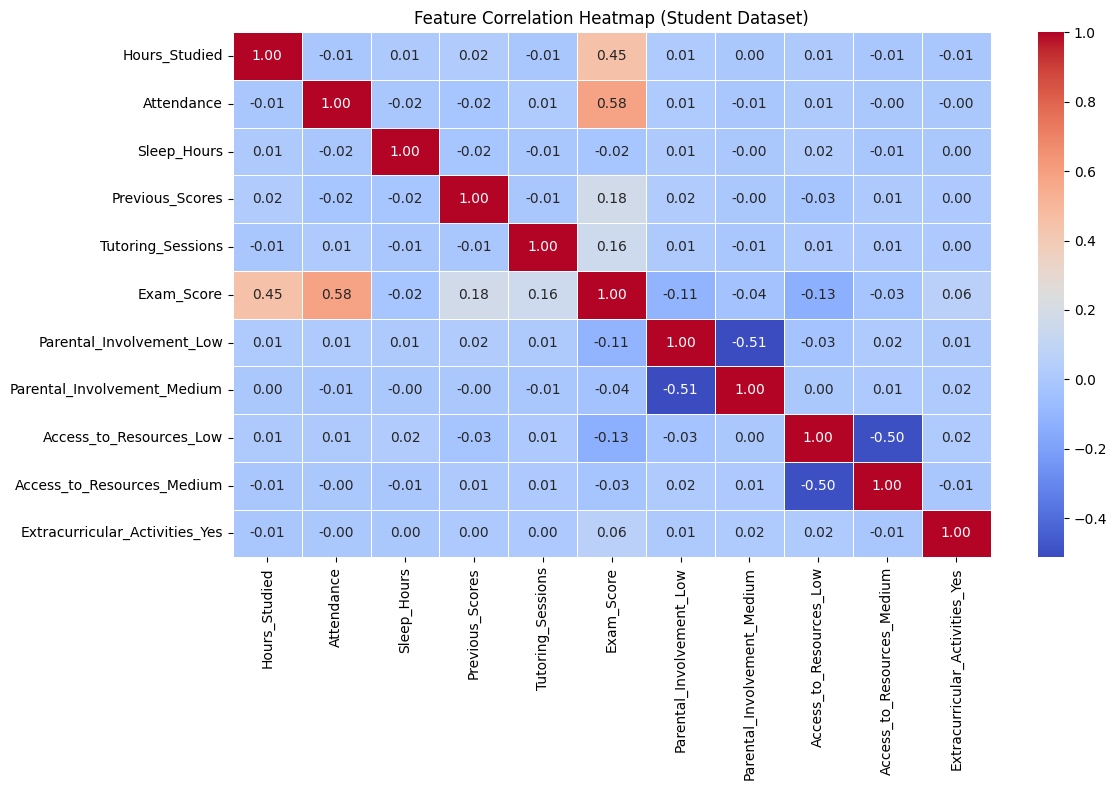

In [50]:
# STEP 8: ENCODE CATEGORICAL FEATURES
# We already prepared student_df_encoded previously.
# Let's inspect the correlation of the encoded student features with the target variable.
plt.figure(figsize=(12, 8))
correlation = student_df_encoded.corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Feature Correlation Heatmap (Student Dataset)")
plt.tight_layout()
plt.show()

In [51]:
# STEP 9: SELECT X AND Y VARIABLES
X = X_student.copy()
y = y_student.copy()

print("Final Selected Features for Modeling:\n", X.columns.tolist())
print("X Shape:", X.shape)
print("y Shape:", y.shape)

Final Selected Features for Modeling:
 ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Parental_Involvement_Low', 'Parental_Involvement_Medium', 'Access_to_Resources_Low', 'Access_to_Resources_Medium', 'Extracurricular_Activities_Yes']
X Shape: (6607, 10)
y Shape: (6607,)


In [52]:
# STEP 10: CONFIRM PREPROCESSING COMPLETION
print("Preprocessing systematically complete. Ready for train-test splitting and model building.")

Preprocessing systematically complete. Ready for train-test splitting and model building.


In [53]:
# STEP 10: HANDLE MISSING VALUES (Placeholder)
# Imputation has been moved to Step 11 to prevent data leakage from the test split.
print("Imputation is now handled dynamically within the Train/Test split step.")

Imputation is now handled dynamically within the Train/Test split step.


In [54]:
# STEP 11: TRAIN TEST SPLIT AND IMPUTATION (Student Dataset)

X_train, X_test, y_train, y_test = train_test_split(
    X_student,
    y_student,
    test_size=0.20,
    random_state=42
)

# Impute any remaining missing values using the training set median
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Student Training Data:", X_train.shape)
print("Student Testing Data:", X_test.shape)

Student Training Data: (5285, 10)
Student Testing Data: (1322, 10)


In [55]:
# STEP 12: FEATURE SCALING

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [56]:
# STEP 13: LINEAR REGRESSION

lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

lr_mae = mean_absolute_error(y_test, lr_pred)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression")
print("MAE:", lr_mae)
print("RMSE:", lr_rmse)
print("R2 Score:", lr_r2)

Linear Regression
MAE: 0.9373227684882786
RMSE: 2.0296866172490766
R2 Score: 0.7085527667372897


In [57]:
# STEP 14: RANDOM FOREST REGRESSION
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Training on scaled features for consistency
rf_model.fit(X_train_scaled, y_train)

rf_pred = rf_model.predict(X_test_scaled)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("\nRandom Forest Regression")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


Random Forest Regression
MAE: 1.2050319761171822
RMSE: 2.214052795720844
R2 Score: 0.6532009445594624


In [58]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train)

poly_pred = poly_model.predict(X_test_poly)

poly_mae = mean_absolute_error(y_test, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))
poly_r2 = r2_score(y_test, poly_pred)

print("Polynomial Regression")
print("MAE:", poly_mae)
print("RMSE:", poly_rmse)
print("R2 Score:", poly_r2)

Polynomial Regression
MAE: 0.9552396965450679
RMSE: 2.047004506373532
R2 Score: 0.7035581206179915


In [59]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_scaled, y_train)

ridge_pred = ridge_model.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression")
print("MAE:", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)

Ridge Regression
MAE: 0.9373366760150926
RMSE: 2.029680283565355
R2 Score: 0.7085545856700266


In [60]:
lasso_model = Lasso(alpha=0.01, max_iter=10000)

lasso_model.fit(X_train_scaled, y_train)

lasso_pred = lasso_model.predict(X_test_scaled)

lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso Regression")
print("MAE:", lasso_mae)
print("RMSE:", lasso_rmse)
print("R2 Score:", lasso_r2)

Lasso Regression
MAE: 0.9374555633600327
RMSE: 2.0282034469337766
R2 Score: 0.7089785545850293


In [61]:
dt_model = DecisionTreeRegressor(
    max_depth=8,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

dt_mae = mean_absolute_error(y_test, dt_pred)
dt_rmse = np.sqrt(mean_squared_error(y_test, dt_pred))
dt_r2 = r2_score(y_test, dt_pred)

print("Decision Tree Regressor")
print("MAE:", dt_mae)
print("RMSE:", dt_rmse)
print("R2 Score:", dt_r2)

Decision Tree Regressor
MAE: 1.5701726420044921
RMSE: 2.581759520187686
R2 Score: 0.5284437180788799


In [62]:
svr_model = SVR(kernel="rbf", C=10, epsilon=0.1)

svr_model.fit(X_train_scaled, y_train)

svr_pred = svr_model.predict(X_test_scaled)

svr_mae = mean_absolute_error(y_test, svr_pred)
svr_rmse = np.sqrt(mean_squared_error(y_test, svr_pred))
svr_r2 = r2_score(y_test, svr_pred)

print("Support Vector Regression")
print("MAE:", svr_mae)
print("RMSE:", svr_rmse)
print("R2 Score:", svr_r2)

Support Vector Regression
MAE: 1.0125931733204607
RMSE: 2.0845270109424874
R2 Score: 0.6925906911597569


In [63]:
knn_model = KNeighborsRegressor(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

knn_mae = mean_absolute_error(y_test, knn_pred)
knn_rmse = np.sqrt(mean_squared_error(y_test, knn_pred))
knn_r2 = r2_score(y_test, knn_pred)

print("KNN Regressor")
print("MAE:", knn_mae)
print("RMSE:", knn_rmse)
print("R2 Score:", knn_r2)

KNN Regressor
MAE: 1.394704992435704
RMSE: 2.449026482307587
R2 Score: 0.5756844740289284


In [64]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Decision Tree",
        "SVR",
        "KNN",
        "Random Forest"
    ],
    "MAE": [
        lr_mae, poly_mae, ridge_mae, lasso_mae,
        dt_mae, svr_mae, knn_mae, rf_mae
    ],
    "RMSE": [
        lr_rmse, poly_rmse, ridge_rmse, lasso_rmse,
        dt_rmse, svr_rmse, knn_rmse, rf_rmse
    ],
    "R2 Score": [
        lr_r2, poly_r2, ridge_r2, lasso_r2,
        dt_r2, svr_r2, knn_r2, rf_r2
    ]
})

results = results.sort_values(by="R2 Score", ascending=False)

display(results)

,Model,MAE,RMSE,R2 Score
3,Lasso Regression,0.937456,2.028203,0.708979
2,Ridge Regression,0.937337,2.029680,0.708555
0,Linear Regression,0.937323,2.029687,0.708553
1,Polynomial Regression,0.955240,2.047005,0.703558
5,SVR,1.012593,2.084527,0.692591
7,Random Forest,1.205032,2.214053,0.653201
6,KNN,1.394705,2.449026,0.575684
4,Decision Tree,1.570173,2.581760,0.528444


In [65]:
if results.iloc[0]["Model"] == "Linear Regression":
    best_model = lr_model
    best_name = "Linear Regression"
    best_pred = lr_pred

elif results.iloc[0]["Model"] == "Polynomial Regression":
    best_model = poly_model
    best_name = "Polynomial Regression"
    best_pred = poly_pred

elif results.iloc[0]["Model"] == "Ridge Regression":
    best_model = ridge_model
    best_name = "Ridge Regression"
    best_pred = ridge_pred

elif results.iloc[0]["Model"] == "Lasso Regression":
    best_model = lasso_model
    best_name = "Lasso Regression"
    best_pred = lasso_pred

elif results.iloc[0]["Model"] == "Decision Tree":
    best_model = dt_model
    best_name = "Decision Tree"
    best_pred = dt_pred

elif results.iloc[0]["Model"] == "SVR":
    best_model = svr_model
    best_name = "SVR"
    best_pred = svr_pred

elif results.iloc[0]["Model"] == "KNN":
    best_model = knn_model
    best_name = "KNN"
    best_pred = knn_pred

elif results.iloc[0]["Model"] == "Random Forest":
    best_model = rf_model
    best_name = "Random Forest"
    best_pred = rf_pred

best_scaler = scaler

print("Best Model:", best_name)
print("Best R2 Score:", results.iloc[0]["R2 Score"])

Best Model: Lasso Regression
Best R2 Score: 0.7089785545850293


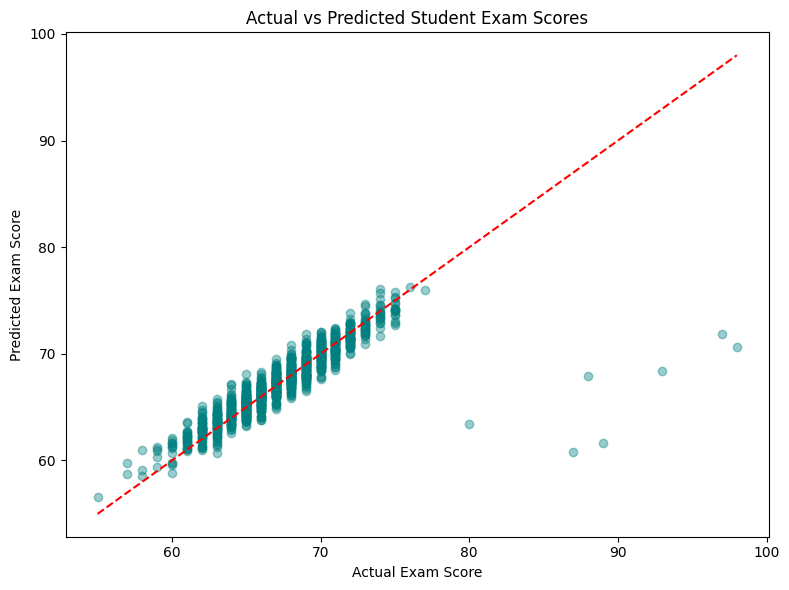

In [66]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_pred, alpha=0.4, color='teal')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    color='red'
)

plt.title("Actual vs Predicted Student Exam Scores")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")

plt.tight_layout()
plt.show()

In [67]:
joblib.dump(
    {
        "model": best_model,
        "scaler": best_scaler,
        "features": X_student.columns.tolist(),
        "model_name": best_name
    },
    "student_marks_prediction_model.pkl"
)

['student_marks_prediction_model.pkl']

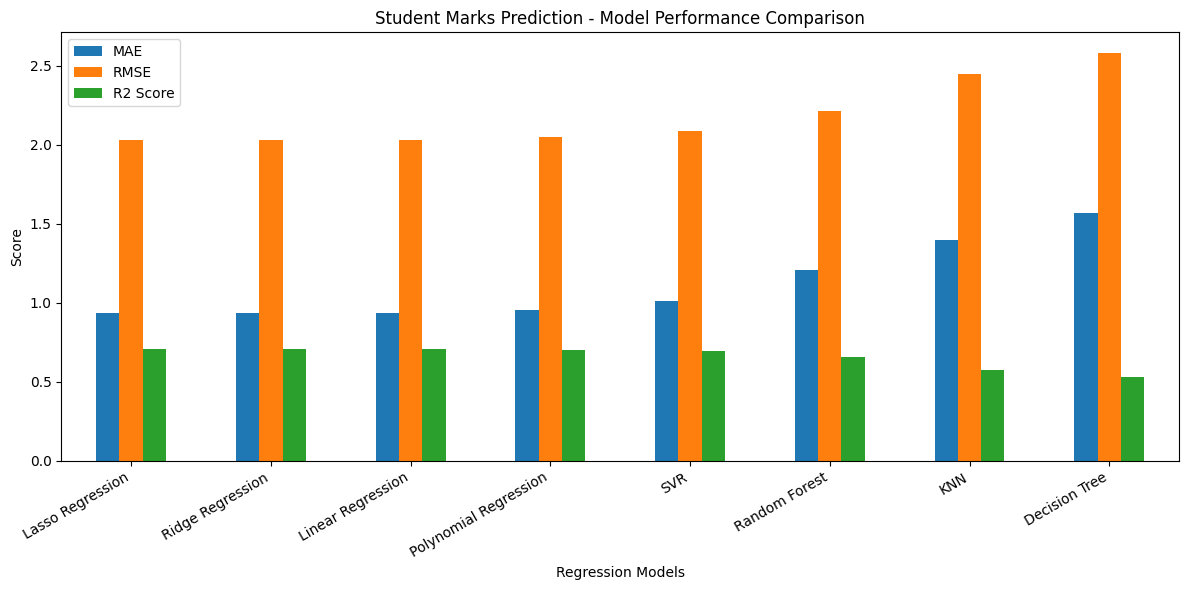

In [68]:
results.set_index("Model")[["MAE", "RMSE", "R2 Score"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Student Marks Prediction - Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Regression Models")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

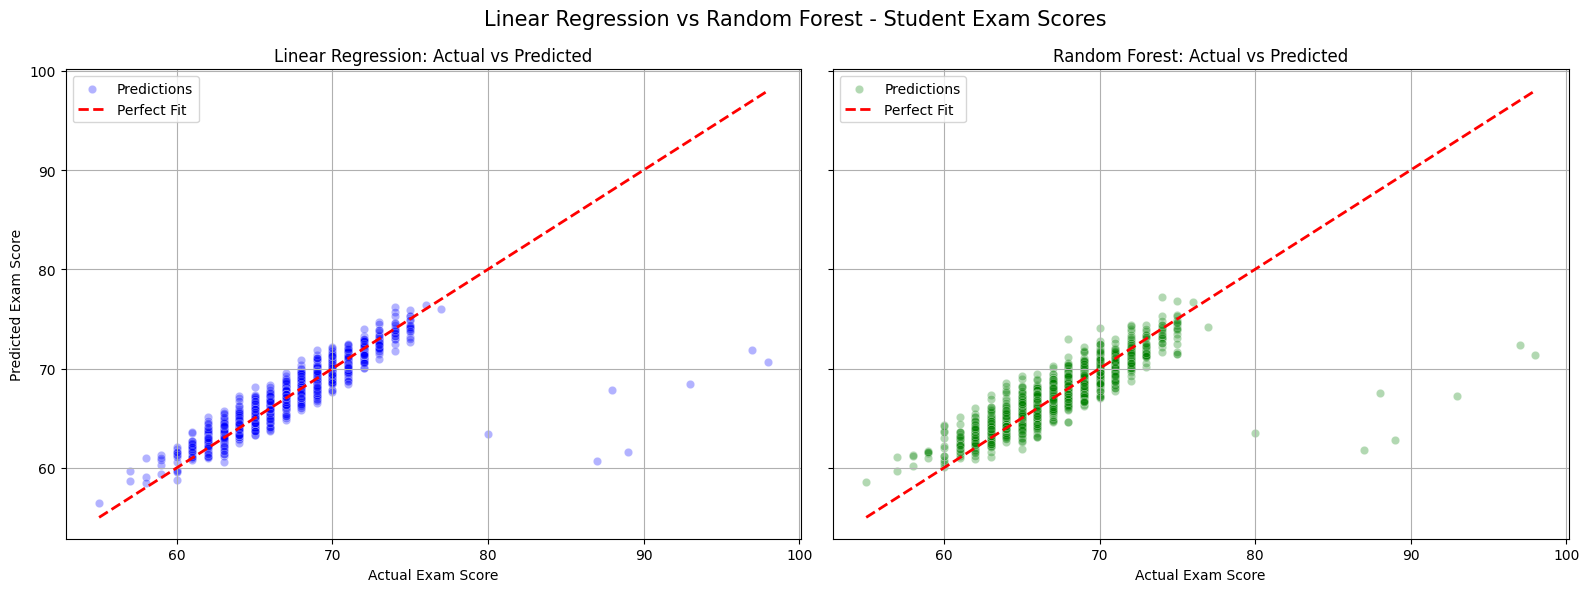

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Subplot 1: Linear Regression
sns.scatterplot(
    x=y_test, y=lr_pred,
    ax=axes[0], alpha=0.3,
    color='blue', label='Predictions'
)

axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red', linestyle='--', linewidth=2,
    label='Perfect Fit'
)

axes[0].set_title("Linear Regression: Actual vs Predicted")
axes[0].set_xlabel("Actual Exam Score")
axes[0].set_ylabel("Predicted Exam Score")
axes[0].legend()
axes[0].grid(True)


# Subplot 2: Random Forest
sns.scatterplot(
    x=y_test, y=rf_pred,
    ax=axes[1], alpha=0.3,
    color='green', label='Predictions'
)

axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red', linestyle='--', linewidth=2,
    label='Perfect Fit'
)

axes[1].set_title("Random Forest: Actual vs Predicted")
axes[1].set_xlabel("Actual Exam Score")
axes[1].legend()
axes[1].grid(True)

plt.suptitle(
    "Linear Regression vs Random Forest - Student Exam Scores",
    fontsize=15
)

plt.tight_layout()
plt.show()

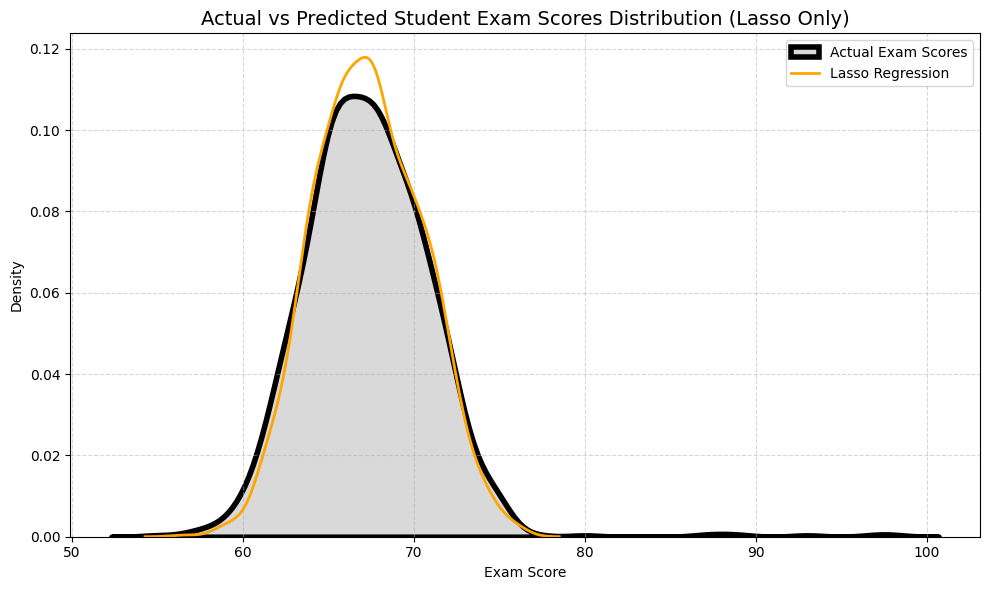

In [70]:
plt.figure(figsize=(10, 6))

# Actual Student Marks Distribution
sns.kdeplot(
    y_test,
    label='Actual Exam Scores',
    color='black',
    linewidth=4,
    fill=True,
    alpha=0.15
)

# Lasso Regression Only
sns.kdeplot(lasso_pred, label='Lasso Regression', color='orange', linewidth=2, linestyle='-')

plt.title("Actual vs Predicted Student Exam Scores Distribution (Lasso Only)", fontsize=14)
plt.xlabel("Exam Score")
plt.ylabel("Density")

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()